In [14]:
import numpy as np
from numba import njit
import matplotlib.pyplot as plt
import mplhep as hep

# Exercises

For the exam prepare two of these exercises, pick those that are more useful for your PhD research. One is about numba, one is about decorators, and one is about multiprocessing.

## Q1: The stock market

(This is about numba)

A Markov Chain is defined as a sequence of random variables where a parameter depends *only* on the preceding value. This is a crucial tool in statistics, widely used in science and beyond (economics for instance).

For instance, the stock market has phases of growing prices (bull), dreasing prices (bear) and recession. This would be a Markov Chain model:

![](https://upload.wikimedia.org/wikipedia/commons/thumb/9/95/Finance_Markov_chain_example_state_space.svg/400px-Finance_Markov_chain_example_state_space.svg.png)

where the numbers on the arrows indicate the probability that the next day will be in a given state.

Your task is to simulate the stock market according to this rule. Start from a random state and simulate many many  iterations. If your code is right, the fraction of days in each state should converge. 

Implement a pure-python version and a numba version, and compare speeds. 


In [15]:
P = np.array([
    [0.90, 0.075, 0.025],   # Bull
    [0.15, 0.80, 0.05],     # Bear
    [0.25, 0.25, 0.50]      # Stagnant
])

In [16]:
def simulate_market(nsteps, P):
    
    state = np.random.randint(0, 3) # random state

    counts = np.zeros(3, dtype=np.int64) # count how many days are spent in each state

    for _ in range(nsteps):
        counts[state] += 1

        r = np.random.random()

        if r < P[state, 0]:
            state = 0
        elif r < P[state, 0] + P[state, 1]:
            state = 1
        else:
            state = 2

    return counts / nsteps

In [25]:
N = 1_000_000

In [26]:
fractions_python = simulate_market(N, P)

In [27]:
print("Pure Python:")
print("Bull     :", fractions_python[0])
print("Bear     :", fractions_python[1])
print("Stagnant :", fractions_python[2])

Pure Python:
Bull     : 0.625271
Bear     : 0.312598
Stagnant : 0.062131


In [28]:
fast_simulate_market = njit(simulate_market)

# Warm-up: compile the function
fast_simulate_market(10, P)

# Actual simulation
fractions_numba = fast_simulate_market(N, P)

print("\nNumba:")
print("Bull     :", fractions_numba[0])
print("Bear     :", fractions_numba[1])
print("Stagnant :", fractions_numba[2])


Numba:
Bull     : 0.62471
Bear     : 0.312951
Stagnant : 0.062339


In [29]:
print("Pure Python:")
%timeit -r 3 -n 1 simulate_market(N, P)

print("Numba:")
%timeit -r 3 -n 1 fast_simulate_market(N, P)

Pure Python:
1.37 s ± 21.7 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)
Numba:
18.5 ms ± 511 μs per loop (mean ± std. dev. of 3 runs, 1 loop each)


## Q2: Consistent plotting

(This is about python's decorators)

Write a decorator for the plots of all your papers. 

- Remember a decorator takes a function. 
- This function in turn should return a matplotlib figure object.
- Before the function is called, the decorator should initialize a matplotlib figure with the options that you like the most (fontsize, ticks, etc etc)
- After the figure it's done, the decorator should save it to pdf.

This is a great hack for your papers! You do this once and for all, and all plots in your paper will be beautifull, all with the same style/fontsize/etc. All you'll need to do is adding `@myplot` to the relevant plotting functions. 
    
The decorator that I use for my papers is available in my python module [skywalker](https://github.com/dgerosa/skywalker/blob/master/skywalker/skywalker.py#L31).  

In [30]:
def invariant_mass(pt1, eta1, phi1,
                   pt2, eta2, phi2):

    px1 = pt1 * np.cos(phi1)
    py1 = pt1 * np.sin(phi1)
    pz1 = pt1 * np.sinh(eta1)
    E1  = pt1 * np.cosh(eta1)

    px2 = pt2 * np.cos(phi2)
    py2 = pt2 * np.sin(phi2)
    pz2 = pt2 * np.sinh(eta2)
    E2  = pt2 * np.cosh(eta2)

    E  = E1 + E2
    px = px1 + px2
    py = py1 + py2
    pz = pz1 + pz2

    m2 = E**2 - px**2 - py**2 - pz**2

    return np.sqrt(np.maximum(m2, 0))

In [31]:
def myplot(function):

    def wrapper(*args, **kwargs):

        plt.rcParams.update({
            "font.size": 14,
            "axes.labelsize": 14,
            "xtick.labelsize": 12,
            "ytick.labelsize": 12
        })

        plt.figure(figsize=(8, 6), dpi = 200)

        fig = function(*args, **kwargs)

        fig.tight_layout()
        fig.savefig(function.__name__ + ".pdf")

        return fig

    return wrapper

In [32]:
@myplot
def plot_ditau_mass(pt1, eta1, phi1,
                    pt2, eta2, phi2):

    mass = invariant_mass(
        pt1, eta1, phi1,
        pt2, eta2, phi2
    )

    fig = plt.gcf()
    ax = plt.gca()

    ax.hist(
        mass,
        bins=40,
        range=(80, 170),
        histtype="step",
        linewidth=2
    )

    ax.axvline(125, linestyle="--", label=r"$m_H = 125$ GeV")

    ax.set_xlabel(r"$m_{\tau\tau}$ [GeV]")
    ax.set_ylabel("Events")
    
    hep.cms.label(
        "Private Work",
        data=False,
        com=14,
        ax=ax
    )
        
    ax.legend()

    return fig

In [33]:
N = 10000

# toy Higgs mass
mH = np.random.normal(125, 8, N)

# H -> tau tau in the Higgs rest frame
p = mH / 2

cos_theta = np.random.uniform(-1, 1, N)
theta = np.arccos(cos_theta)

phi1 = np.random.uniform(-np.pi, np.pi, N)
phi2 = phi1 + np.pi
phi2 = (phi2 + np.pi) % (2*np.pi) - np.pi

pt1 = p * np.sin(theta)
pt2 = pt1

eta1 = -np.log(np.tan(theta / 2))
eta2 = -eta1

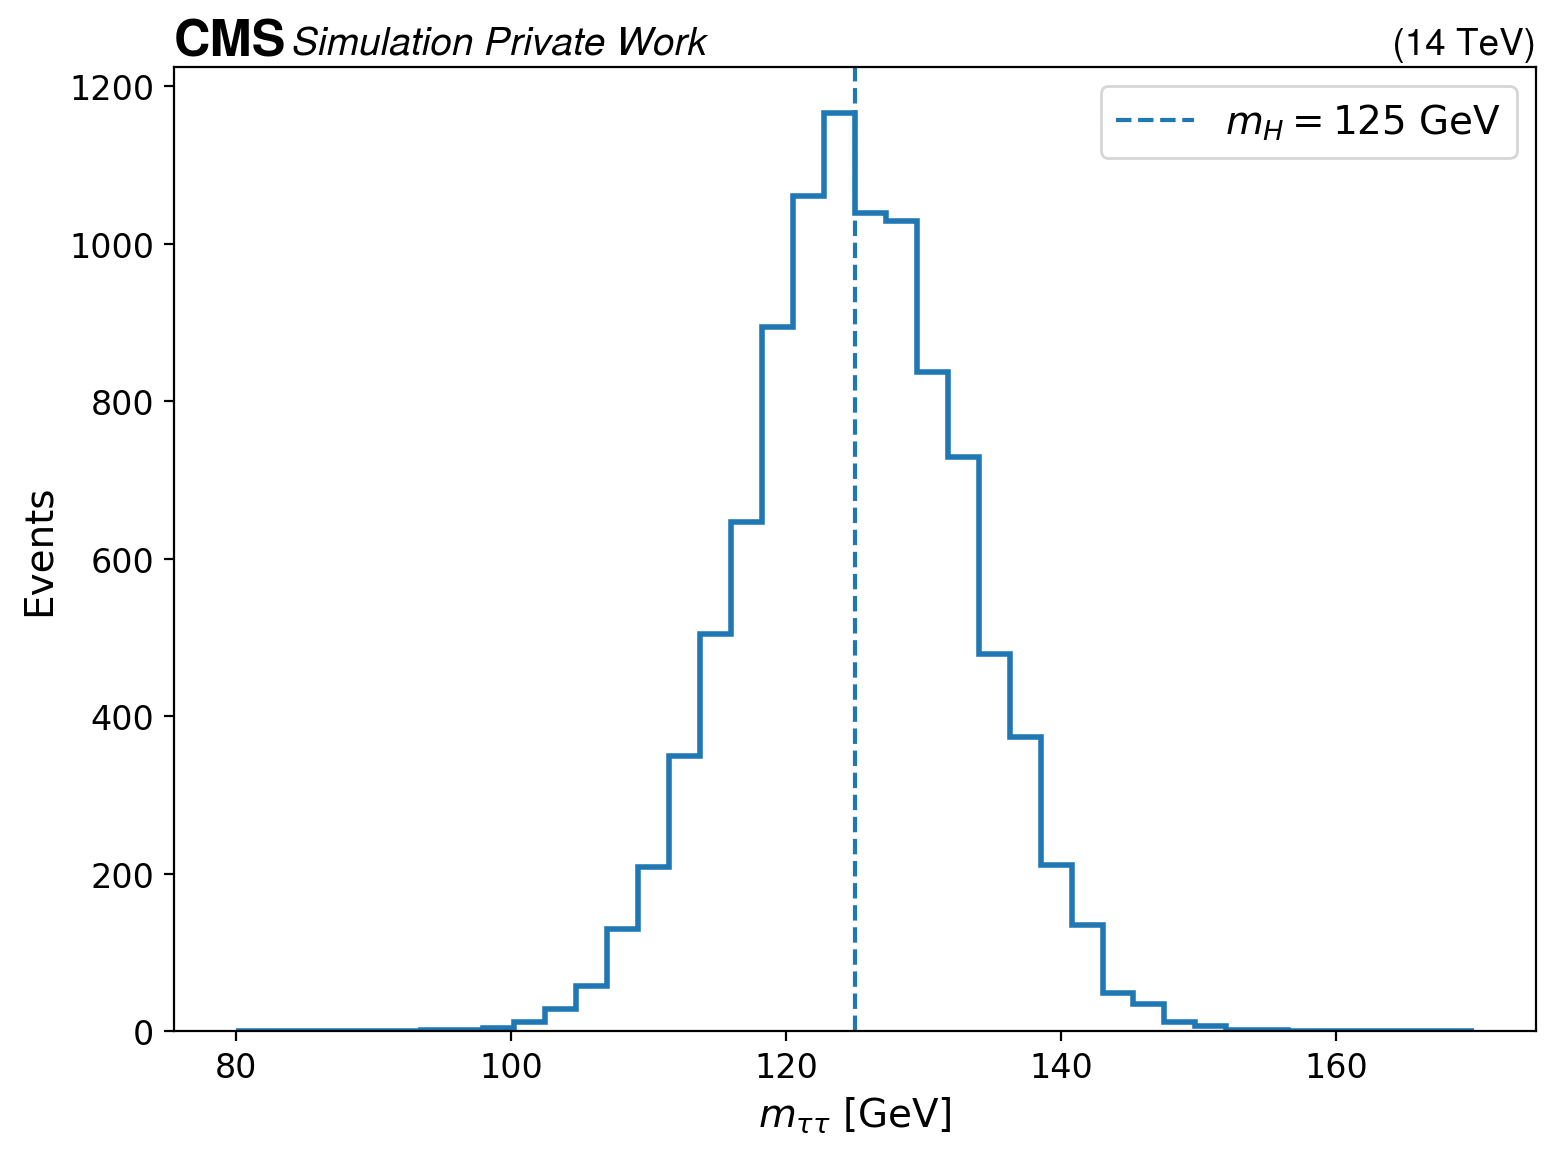

In [34]:
fig = plot_ditau_mass(
    pt1, eta1, phi1,
    pt2, eta2, phi2
)